# SHA departure-time research analysis

This documented notebook reproduces exploratory analyses for the accompanying report. Its three research questions are: (1) what is the distribution of the recorded scheduled-to-actual departure timestamp difference; (2) how does it vary by scheduled local hour; and (3) does a morning-evening contrast persist within the same route and weekday? The original carrier comparison is omitted because the supplied `operating_carrier` field is blank and unverified on every row. The proposed revised scope still needs instructor approval. Run cells from top to bottom with the project **Python 3 (uv)** kernel.

## 1. Import tools and load the data

This notebook uses Python's built-in `csv` module and Matplotlib. The CSV is expected in the project root next to this notebook.

In [1]:
import csv
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt

data_path = Path("sha_master.csv")

with data_path.open(newline="", encoding="utf-8-sig") as csv_file:
    flights = list(csv.DictReader(csv_file))

print("Flight records:", len(flights))
print("Example record:")
flights[0]

Flight records: 23705
Example record:


{'event_id': 'sha_25e4eff64f60c3005a65b590:arrival',
 'canonical_id': 'sha_25e4eff64f60c3005a65b590',
 'direction': 'arrival',
 'scheduled_utc': '2026-09-21T23:55:00.000Z',
 'scheduled_sha_local': '2026-09-22T07:55:00.000+08:00',
 'flight_number': '9C8946',
 'flight_numbers': '9C8946',
 'source_airline_designators': '9C',
 'canonical_airline_designator': '9C',
 'status_display': 'Landed 7:46 AM',
 'identity_review': 'false',
 'origin_iata': 'XIY',
 'destination_iata': 'SHA',
 'route': 'XIY-SHA',
 'local_date': '2026-09-22',
 'local_hour': '7',
 'weekday': 'Tuesday',
 'national_day_phase': 'before',
 'public_holiday': 'none',
 'adjusted_workday': 'false',
 'calendar_day_type': 'ordinary_weekday',
 'holiday_calendar_source': 'https://www.gov.cn/zhengce/content/202511/content_7047090.htm',
 'operating_carrier': '',
 'operating_carrier_verified': 'false',
 'completed_for_timing_readiness': 'true',
 'actual_event_utc': '2026-09-21T23:46:17.000Z',
 'timing_difference_minutes': '-8.7166666666

## 2. Scheduled flights per day

Count arrivals and departures for each local date, then compare their daily totals.

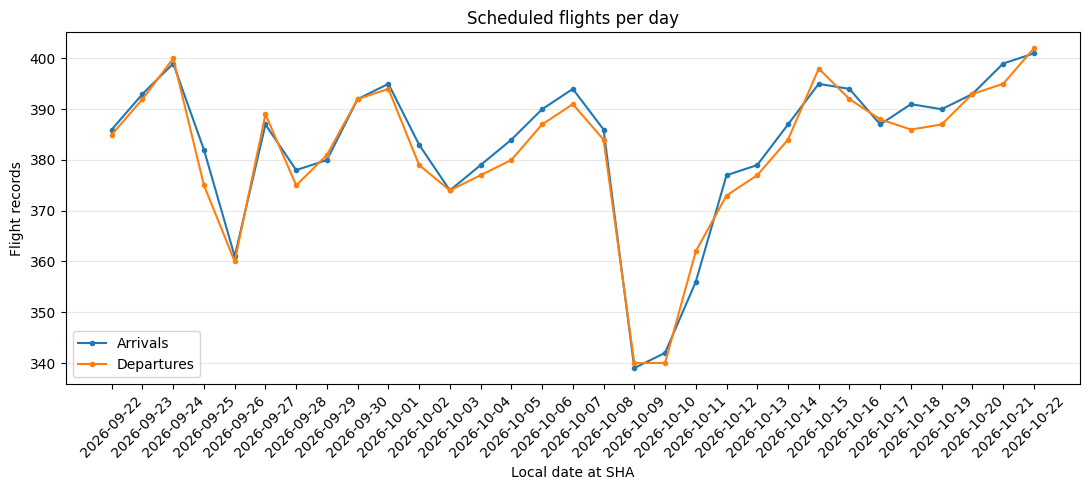

In [2]:
daily_counts = defaultdict(Counter)
for flight in flights:
    daily_counts[flight["local_date"]][flight["direction"]] += 1

dates = sorted(daily_counts)
fig, ax = plt.subplots(figsize=(11, 5))
for direction, label in [("arrival", "Arrivals"), ("departure", "Departures")]:
    ax.plot(
        dates,
        [daily_counts[date][direction] for date in dates],
        marker="o",
        markersize=3,
        label=label,
    )

ax.set(title="Scheduled flights per day", xlabel="Local date at SHA", ylabel="Flight records")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## 3. Scheduled flights by local hour

Compare when arrivals and departures are scheduled throughout the day. Hours are local to Shanghai (24-hour clock).

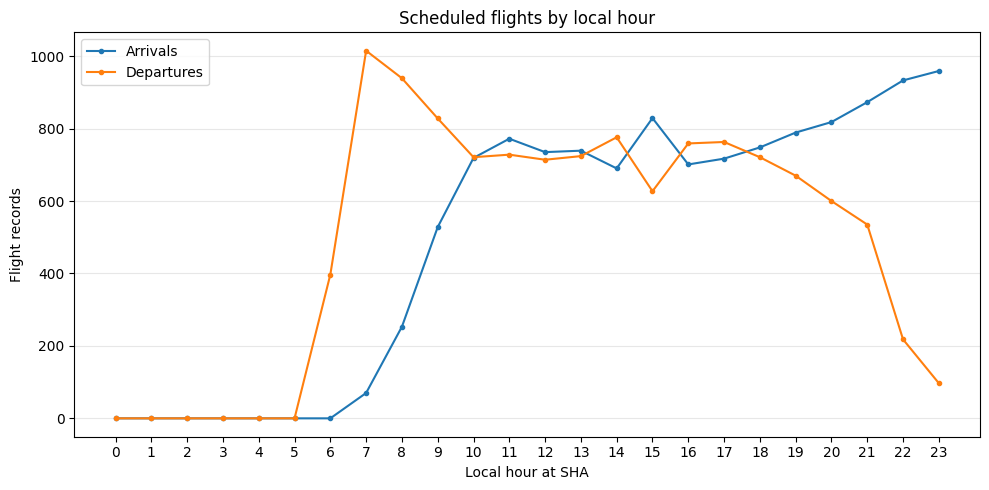

In [3]:
hourly_counts = defaultdict(Counter)
for flight in flights:
    hour = int(flight["local_hour"])
    hourly_counts[hour][flight["direction"]] += 1

hours = range(24)
fig, ax = plt.subplots(figsize=(10, 5))
for direction, label in [("arrival", "Arrivals"), ("departure", "Departures")]:
    ax.plot(
        hours,
        [hourly_counts[hour][direction] for hour in hours],
        marker="o",
        markersize=3,
        label=label,
    )

ax.set(title="Scheduled flights by local hour", xlabel="Local hour at SHA", ylabel="Flight records")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## 4. Most frequent routes

Routes are directional: for example, `SHA-SZX` and `SZX-SHA` are counted separately.

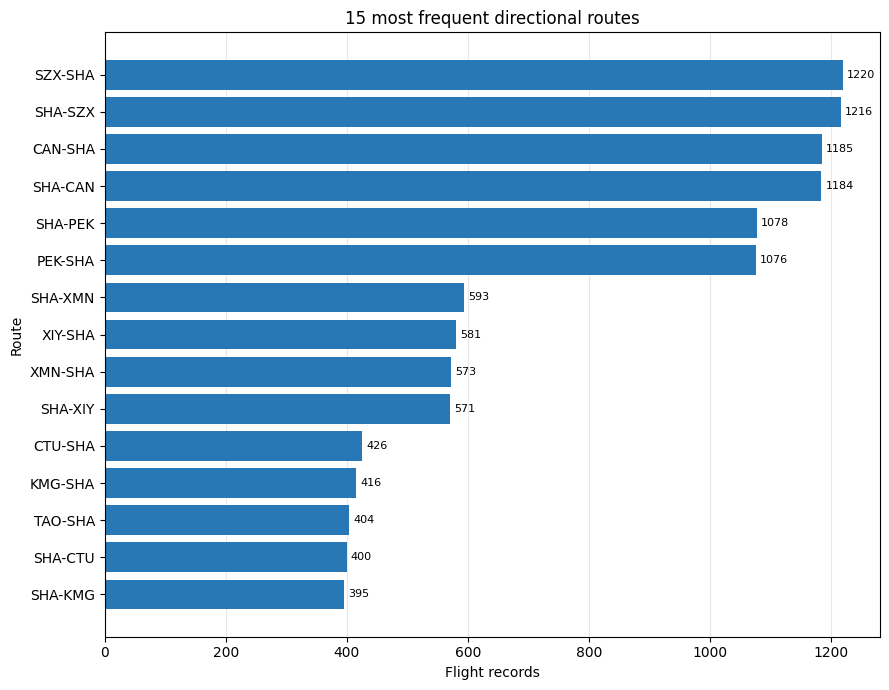

In [4]:
route_counts = Counter(flight["route"] for flight in flights)
top_routes = route_counts.most_common(15)
route_labels = [route for route, count in reversed(top_routes)]
route_values = [count for route, count in reversed(top_routes)]

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(route_labels, route_values, color="#2878B5")
ax.bar_label(bars, padding=3, fontsize=8)
ax.set(title="15 most frequent directional routes", xlabel="Flight records", ylabel="Route")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 5. Cancellation rate by calendar day type

The rate is cancellations divided by records with a known status in each category. Blank and `Unknown` statuses are excluded from the denominator.

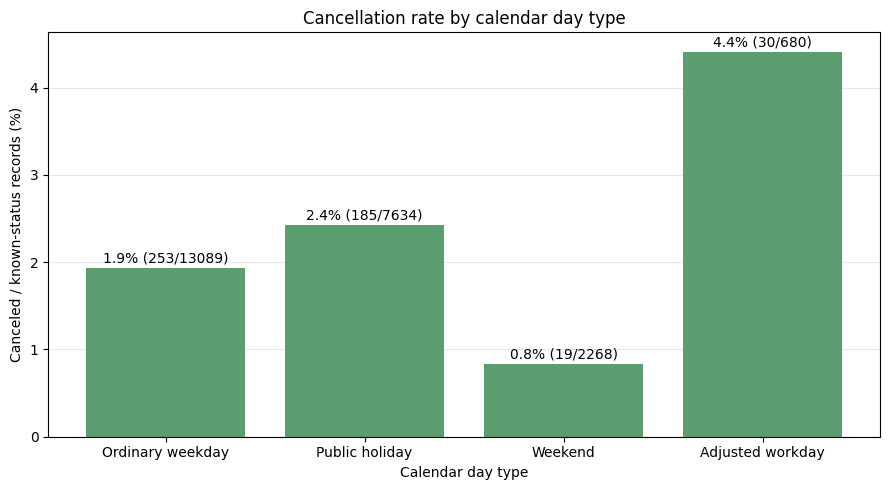

Unknown or blank status excluded: 34


In [5]:
calendar_labels = {
    "ordinary_weekday": "Ordinary weekday",
    "public_holiday": "Public holiday",
    "weekend": "Weekend",
    "adjusted_workday": "Adjusted workday",
}
status_totals = Counter()
cancellations = Counter()
unknown_statuses = 0

for flight in flights:
    category = flight["calendar_day_type"]
    status = flight["status_display"].strip().casefold()
    if not status or status == "unknown":
        unknown_statuses += 1
        continue
    status_totals[category] += 1
    if status == "canceled":
        cancellations[category] += 1

categories = [category for category in calendar_labels if status_totals[category]]
rates = [100 * cancellations[category] / status_totals[category] for category in categories]
labels = [calendar_labels[category] for category in categories]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, rates, color="#5A9E6F")
for bar, category in zip(bars, categories):
    ax.annotate(
        "{:.1f}% ({}/{})".format(
            100 * cancellations[category] / status_totals[category],
            cancellations[category],
            status_totals[category],
        ),
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
    )

ax.set(title="Cancellation rate by calendar day type", xlabel="Calendar day type", ylabel="Canceled / known-status records (%)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
print("Unknown or blank status excluded:", unknown_statuses)

## Measurement note and revised scope

The dataset marks `timing_semantics_verified` false for all 23,705 rows, and `operating_carrier` is blank while `operating_carrier_verified` is false for all rows. We therefore calculate a **recorded timestamp difference** as `actual_departure_utc - scheduled_departure_utc`, not a validated operational delay, and do not compare carriers. The CSV covers 31 local dates (2026-09-22 through 2026-10-22). Canceled flights, unknown/blank statuses, and records without both departure timestamps are excluded from the deviation analyses. The requested route-weekday-hour scope is a proposed revision and should be cleared with the instructor before submission.

## 6. Research question 1: what is the distribution of recorded departure-time differences?

Define the outcome as actual departure UTC minus scheduled departure UTC, in minutes. Positive values are later recorded timestamps; negative values are earlier. Summarize the full sample and separate the early and late observations. The morning-evening boxplot is a descriptive preview; the next section examines every scheduled hour.

Included departures: 11560
Excluded departures: {'canceled': 246, 'missing departure timestamp': 10, 'unknown/blank status': 16}
Maximum difference from stored timing_difference_minutes: 0.000000 minutes
Identity-review sensitivity: n=27 including flagged records; median with all=17.3, without flagged=17.3 minutes
Full sample: n=11560, median=17.3, mean=22.1, Q1=11.4, Q3=25.6, IQR=14.2, P90=35.1, P95=55.6, min=-7.4, max=590.0 minutes
Early (<0): n=71, median=-1.2 min; late (>0): n=11489, median=17.4 min
At least 15 minutes later: 59.9%; at least 30 minutes later: 16.0%
Morning and evening windows (scheduled local time):
Morning (06–11): n=4531, median=18.9 min, mean=21.7 min, P95=44.2 min
Evening (17–22): n=3406, median=16.0 min, mean=22.9 min, P95=72.7 min


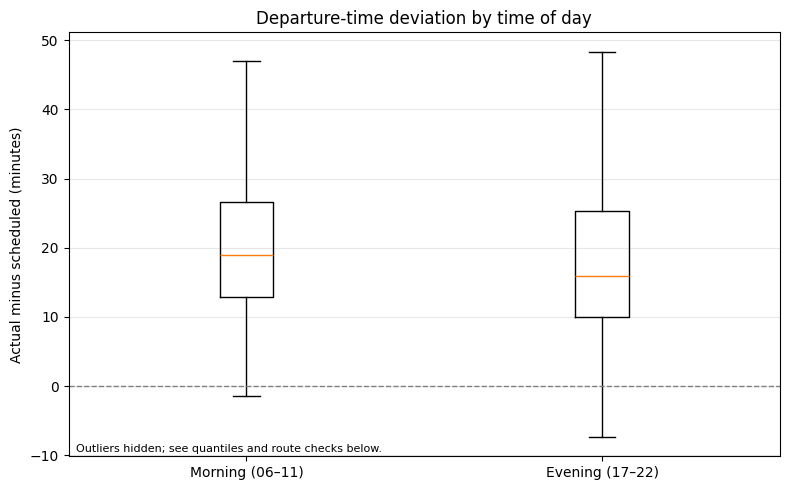

In [6]:
from datetime import datetime
import statistics

def departure_deviation_minutes(flight):
    """Calculate recorded actual minus scheduled departure, in minutes."""
    scheduled = datetime.fromisoformat(flight["scheduled_departure_utc"].replace("Z", "+00:00"))
    actual = datetime.fromisoformat(flight["actual_departure_utc"].replace("Z", "+00:00"))
    return (actual - scheduled).total_seconds() / 60

def percentile(values, fraction):
    ordered = sorted(values)
    position = (len(ordered) - 1) * fraction
    lower = int(position)
    upper = min(lower + 1, len(ordered) - 1)
    weight = position - lower
    return ordered[lower] * (1 - weight) + ordered[upper] * weight

departure_records = []
excluded_departures = Counter()
for flight in flights:
    if flight["direction"] != "departure":
        continue
    status = flight["status_display"].strip().casefold()
    if status == "canceled":
        excluded_departures["canceled"] += 1
        continue
    if not status or status == "unknown":
        excluded_departures["unknown/blank status"] += 1
        continue
    if not flight["actual_departure_utc"] or not flight["scheduled_departure_utc"]:
        excluded_departures["missing departure timestamp"] += 1
        continue
    departure_records.append({
        **flight,
        "deviation_minutes": departure_deviation_minutes(flight),
        "hour": int(flight["local_hour"]),
    })

morning = [r["deviation_minutes"] for r in departure_records if 6 <= r["hour"] < 12]
evening = [r["deviation_minutes"] for r in departure_records if 17 <= r["hour"] < 23]
print("Included departures:", len(departure_records))
print("Excluded departures:", dict(excluded_departures))
all_differences = [record["deviation_minutes"] for record in departure_records]
difference_check = max(
    abs(record["deviation_minutes"] - float(record["timing_difference_minutes"]))
    for record in departure_records
)
identity_reviewed = [record for record in departure_records if record["identity_review"] == "true"]
without_identity_review = [record["deviation_minutes"] for record in departure_records if record["identity_review"] != "true"]
print("Maximum difference from stored timing_difference_minutes: {:.6f} minutes".format(difference_check))
print("Identity-review sensitivity: n={} including flagged records; median with all={:.1f}, without flagged={:.1f} minutes".format(
    len(identity_reviewed), statistics.median(all_differences), statistics.median(without_identity_review)
))
early = [value for value in all_differences if value < 0]
late = [value for value in all_differences if value > 0]
print("Full sample: n={}, median={:.1f}, mean={:.1f}, Q1={:.1f}, Q3={:.1f}, IQR={:.1f}, P90={:.1f}, P95={:.1f}, min={:.1f}, max={:.1f} minutes".format(
    len(all_differences), statistics.median(all_differences), statistics.mean(all_differences),
    percentile(all_differences, 0.25), percentile(all_differences, 0.75),
    percentile(all_differences, 0.75) - percentile(all_differences, 0.25),
    percentile(all_differences, 0.90), percentile(all_differences, 0.95),
    min(all_differences), max(all_differences),
))
print("Early (<0): n={}, median={:.1f} min; late (>0): n={}, median={:.1f} min".format(
    len(early), statistics.median(early), len(late), statistics.median(late)
))
print("At least 15 minutes later: {:.1%}; at least 30 minutes later: {:.1%}".format(
    sum(value >= 15 for value in all_differences) / len(all_differences),
    sum(value >= 30 for value in all_differences) / len(all_differences),
))
print("Morning and evening windows (scheduled local time):")
for label, values in [("Morning (06–11)", morning), ("Evening (17–22)", evening)]:
    print("{}: n={}, median={:.1f} min, mean={:.1f} min, P95={:.1f} min".format(
        label, len(values), statistics.median(values), statistics.mean(values), percentile(values, 0.95)
    ))

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([morning, evening], showfliers=False)
ax.set_xticks([1, 2], ["Morning (06–11)", "Evening (17–22)"])
ax.axhline(0, color="gray", linewidth=1, linestyle="--")
ax.set(title="Departure-time deviation by time of day", ylabel="Actual minus scheduled (minutes)")
ax.text(0.01, 0.01, "Outliers hidden; see quantiles and route checks below.", transform=ax.transAxes, fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 7. Research question 2: how does the recorded difference vary by scheduled hour?

The table and chart below show the number of included records, median and 90th percentile for each scheduled local hour. Counts describe schedule concentration only; they are not a direct measure of runway or airspace congestion.

Hour  n    Median   P90
   6  385      10.9   19.1
   7  997      14.7   24.8
   8  913      21.3   32.4
   9  816      26.2   41.5
  10  709      20.0   33.9
  11  711      18.8   34.1
  12  699      15.8   39.4
  13  707      17.5   38.0
  14  766      17.5   33.0
  15  612      14.9   30.9
  16  745      18.0   39.6
  17  740      20.0   43.5
  18  696      19.3   43.7
  19  648      17.2   49.5
  20  591      13.7   42.2
  21  517      11.0   44.7
  22  214       8.1   20.1
  23   94       9.8   20.5


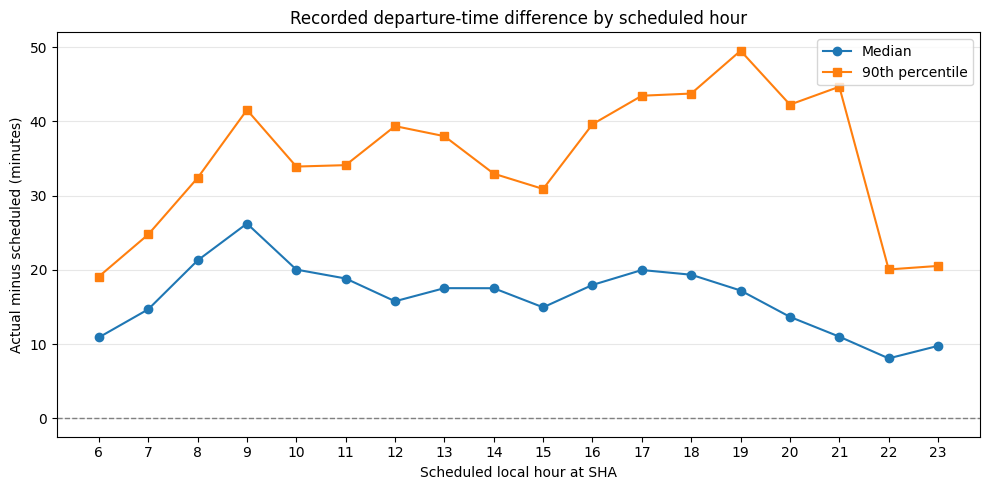

In [7]:
hourly_deviations = defaultdict(list)
for record in departure_records:
    hourly_deviations[record["hour"]].append(record["deviation_minutes"])

print("Hour  n    Median   P90")
for hour in sorted(hourly_deviations):
    values = hourly_deviations[hour]
    print("{:>4} {:>4} {:>9.1f} {:>6.1f}".format(
        hour, len(values), statistics.median(values), percentile(values, 0.90)
    ))

hours = sorted(hourly_deviations)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hours, [statistics.median(hourly_deviations[h]) for h in hours], marker="o", label="Median")
ax.plot(hours, [percentile(hourly_deviations[h], 0.90) for h in hours], marker="s", label="90th percentile")
ax.axhline(0, color="gray", linewidth=1, linestyle="--")
ax.set(title="Recorded departure-time difference by scheduled hour", xlabel="Scheduled local hour at SHA", ylabel="Actual minus scheduled (minutes)")
ax.set_xticks(hours)
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Supplementary route check: which routes have the largest variability or extremes?

Rank directional SHA departure routes with at least 30 included flights. Standard deviation measures variability; the 95th percentile of absolute deviation summarizes the tail magnitude; maximum positive deviation is the largest recorded late extreme. The minimum sample threshold reduces unstable rankings from very small samples.


Largest standard deviation (minutes; at least 30 flights)
Route    n      mean       SD   abs-p95   max-late
SHA-PEK  1023      25.8     31.8      71.5      590.0
SHA-KOW    31      27.5     30.1      88.7      138.6
SHA-URC   373      24.2     28.8      52.5      291.6
SHA-SQJ    31      26.6     28.0      58.3      160.8
SHA-HND   124      28.9     26.4      55.2      189.8
SHA-CAN  1168      26.5     25.4      76.4      239.0
SHA-CGO   137      22.5     25.3      65.3      173.0
SHA-PKX   302      24.6     25.2      56.4      305.4
SHA-HKG   176      25.4     25.2      71.4      217.5
SHA-XFN    31      15.8     24.6      64.6      105.8

Largest 95th percentile absolute deviation (minutes; at least 30 flights)
Route    n      mean       SD   abs-p95   max-late
SHA-KOW    31      27.5     30.1      88.7      138.6
SHA-CAN  1168      26.5     25.4      76.4      239.0
SHA-PEK  1023      25.8     31.8      71.5      590.0
SHA-HKG   176      25.4     25.2      71.4      217.5
SHA-SZX 

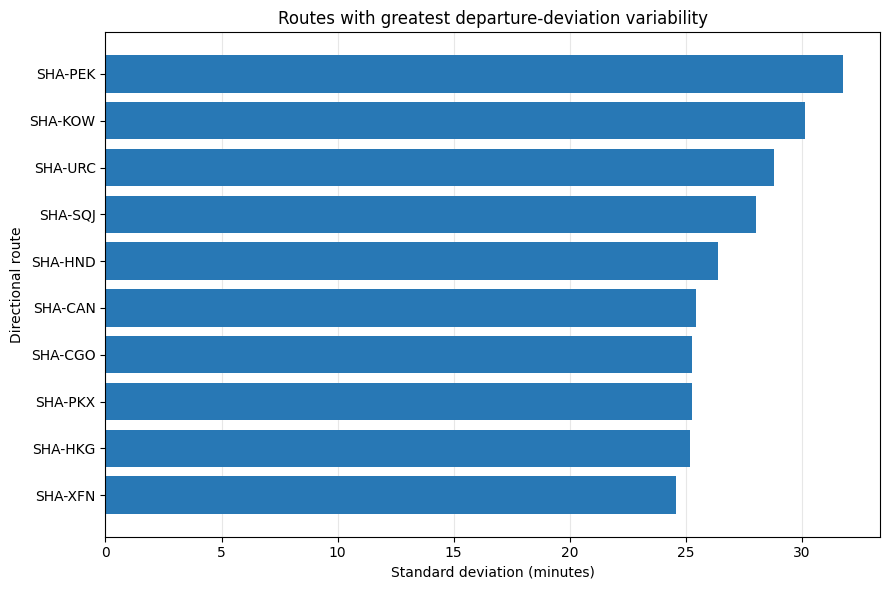

In [8]:
def percentile(values, fraction):
    """Linearly interpolate a percentile from a non-empty sequence."""
    ordered = sorted(values)
    position = (len(ordered) - 1) * fraction
    lower = int(position)
    upper = min(lower + 1, len(ordered) - 1)
    weight = position - lower
    return ordered[lower] * (1 - weight) + ordered[upper] * weight

route_deviations = defaultdict(list)
for record in departure_records:
    route_deviations[record["route"]].append(record["deviation_minutes"])

minimum_route_flights = 30
route_summary = []
for route, values in route_deviations.items():
    if len(values) >= minimum_route_flights:
        route_summary.append({
            "route": route,
            "n": len(values),
            "mean": statistics.mean(values),
            "sd": statistics.stdev(values),
            "absolute_p95": percentile([abs(value) for value in values], 0.95),
            "max_late": max(values),
        })

for metric, title in [
    ("sd", "Largest standard deviation"),
    ("absolute_p95", "Largest 95th percentile absolute deviation"),
    ("max_late", "Worst single late deviation"),
]:
    print("\n" + title + " (minutes; at least {} flights)".format(minimum_route_flights))
    print("Route    n      mean       SD   abs-p95   max-late")
    for row in sorted(route_summary, key=lambda item: item[metric], reverse=True)[:10]:
        print("{route:8} {n:4d} {mean:9.1f} {sd:8.1f} {absolute_p95:9.1f} {max_late:10.1f}".format(**row))

top_variable = sorted(route_summary, key=lambda row: row["sd"], reverse=True)[:10]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([row["route"] for row in reversed(top_variable)], [row["sd"] for row in reversed(top_variable)], color="#2878B5")
ax.set(title="Routes with greatest departure-deviation variability", xlabel="Standard deviation (minutes)", ylabel="Directional route")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 8. Research question 3: does the time-of-day pattern persist within route-weekday groups?

Compare mean deviation within each same directional **route × weekday** group, matching morning (06:00–11:59) and evening (17:00–22:59) services. Keep groups with at least five observations in each time window. Each histogram entry is one matched group; positive values mean the evening group had a larger mean deviation. This controls descriptively for route and weekday, but is not a causal estimate.

Matched route-weekday groups: 173
Median evening-minus-morning difference: -1.0 minutes
Groups with larger evening mean: 45.1%


Date-cluster bootstrap 95% percentile interval: -2.64 to 4.48 minutes (1,000 resamples)


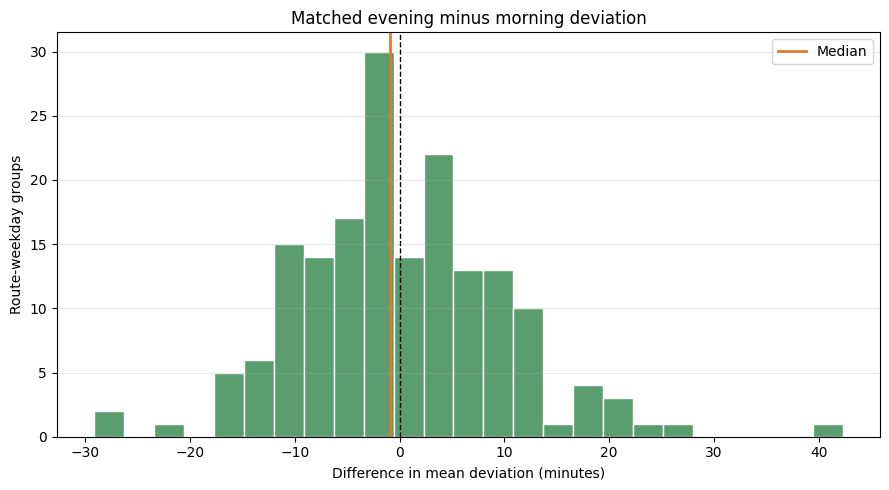

In [9]:
matched_groups = defaultdict(lambda: {"morning": [], "evening": []})
records_by_date = defaultdict(list)
for record in departure_records:
    records_by_date[record["local_date"]].append(record)
    if 6 <= record["hour"] < 12:
        window = "morning"
    elif 17 <= record["hour"] < 23:
        window = "evening"
    else:
        continue
    matched_groups[(record["route"], record["weekday"])][window].append(record["deviation_minutes"])

minimum_per_window = 5
matched_differences = []
for (route, weekday), group in matched_groups.items():
    if len(group["morning"]) >= minimum_per_window and len(group["evening"]) >= minimum_per_window:
        matched_differences.append(
            statistics.mean(group["evening"]) - statistics.mean(group["morning"])
        )

if not matched_differences:
    print("No route-weekday groups met the minimum sample size.")
else:
    import random

    print("Matched route-weekday groups:", len(matched_differences))
    print("Median evening-minus-morning difference: {:.1f} minutes".format(statistics.median(matched_differences)))
    print("Groups with larger evening mean: {:.1%}".format(sum(value > 0 for value in matched_differences) / len(matched_differences)))

    rng = random.Random(4001)
    dates = sorted(records_by_date)
    bootstrap_effects = []
    for _ in range(1000):
        sampled_dates = [rng.choice(dates) for _ in dates]
        bootstrap_groups = defaultdict(lambda: {"morning": [], "evening": []})
        for date in sampled_dates:
            for record in records_by_date[date]:
                if 6 <= record["hour"] < 12:
                    window = "morning"
                elif 17 <= record["hour"] < 23:
                    window = "evening"
                else:
                    continue
                bootstrap_groups[(record["route"], record["weekday"])][window].append(record["deviation_minutes"])
        effects = [
            statistics.mean(group["evening"]) - statistics.mean(group["morning"])
            for group in bootstrap_groups.values()
            if len(group["morning"]) >= minimum_per_window and len(group["evening"]) >= minimum_per_window
        ]
        if effects:
            bootstrap_effects.append(statistics.mean(effects))
    print("Date-cluster bootstrap 95% percentile interval: {:.2f} to {:.2f} minutes (1,000 resamples)".format(
        percentile(bootstrap_effects, 0.025), percentile(bootstrap_effects, 0.975)
    ))

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(matched_differences, bins=25, color="#5A9E6F", edgecolor="white")
    ax.axvline(0, color="black", linewidth=1, linestyle="--")
    ax.axvline(statistics.median(matched_differences), color="#E07A32", linewidth=2, label="Median")
    ax.set(title="Matched evening minus morning deviation", xlabel="Difference in mean deviation (minutes)", ylabel="Route-weekday groups")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

## Selected references

- Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317–372. [https://doi.org/10.3368/jhr.50.2.317](https://doi.org/10.3368/jhr.50.2.317)
- Chen, Y.-H., & Lin, J.-J. (2021). Determinants of flight delays at East Asian airports from an airport, route and network perspective. *Journal of Air Transport Management, 94*, 102064. [https://doi.org/10.1016/j.jairtraman.2021.102064](https://doi.org/10.1016/j.jairtraman.2021.102064)
- Efron, B. (1979). Bootstrap methods: Another look at the jackknife. *The Annals of Statistics, 7*(1), 1–26. [https://doi.org/10.1214/aos/1176344552](https://doi.org/10.1214/aos/1176344552)
- Koenker, R., & Bassett, G., Jr. (1978). Regression quantiles. *Econometrica, 46*(1), 33–50. [https://doi.org/10.2307/1913643](https://doi.org/10.2307/1913643)
- Mayer, C., & Sinai, T. (2003). Network effects, congestion externalities, and air traffic delays: Or why not all delays are evil. *American Economic Review, 93*(4), 1194–1215. [https://doi.org/10.1257/000282803769206269](https://doi.org/10.1257/000282803769206269)
- Pyrgiotis, N., Malone, K. M., & Odoni, A. (2013). Modelling delay propagation within an airport network. *Transportation Research Part C: Emerging Technologies, 27*, 60–75. [https://doi.org/10.1016/j.trc.2011.05.017](https://doi.org/10.1016/j.trc.2011.05.017)

Reference metadata were checked against Crossref/DOI records. These sources provide context and method, not evidence that the timestamp outcome in this dataset is operationally validated. See the accompanying report for the full literature review and references.